# Deteksi Penyakit Padi dengan YOLO26l

Tujuan notebook ini adalah mendeteksi 11 kelas penyakit/kondisi padi dari dataset resmi panitia. Metrik penilaian adalah mAP@50 dan F1.


In [1]:
%pip install -q gdown matplotlib "ultralytics==8.4.187" pyyaml opencv-python


Note: you may need to restart the kernel to use updated packages.


sesuaikan `TRAIN`,`DEVICE`,`WEIGHTS_OVERRIDE` 

- `TRAIN`: `True` menjalankan training; `False` melewati training dan akan menggunakan bobot dari weight_override
- `DEVICE`: gunakan `[0,1]` jika ada dua gpu dan jika hanya punya 1 gpu gunakan device=`[0]`
- `WEIGHTS_OVERRIDE`: jika ingin menggunakan bobot yang diupload github release hasi train, masukkan path nya kesini contoh nya,  WEIGHTS_OVERRIDE = `path/ke/yolo26l_best_717.pt` dan ubah TRAIN menjadi `False`
- File dataset didapat dari link https://drive.usercontent.google.com/download?id=1CAPmwVmYW6499Ic1wx8TFptLV8beDZcX&export=download 
- id gdrive nya = `1CAPmwVmYW6499Ic1wx8TFptLV8beDZcX`

In [2]:
import json
import shutil
import zipfile
from collections import Counter
from pathlib import Path

import cv2
import gdown
import matplotlib.pyplot as plt
import torch
import yaml
from ultralytics import YOLO
from ultralytics.data.converter import convert_coco
from ultralytics.utils.plotting import Annotator, colors

# Sumber dataset 
GDRIVE_FILE_ID = "1CAPmwVmYW6499Ic1wx8TFptLV8beDZcX"
SPLITS = ["train", "valid", "test"]

WORK_DIR = Path.cwd().resolve()
ZIP_PATH = WORK_DIR / "dataset.zip"
RAW_DIR = WORK_DIR / "dataset_raw"
DATASET_DIR = WORK_DIR / "Dataset_Telepati"
DATASET_YAML = DATASET_DIR / "dataset.yaml"
RUNS_DIR = WORK_DIR / "runs"
BEST_WEIGHTS = RUNS_DIR / "train" / "weights" / "best.pt"

TRAIN = True               # False = lewati training (butuh bobot di BEST_WEIGHTS atau WEIGHTS_OVERRIDE)
WEIGHTS_OVERRIDE = None    
EPOCHS = 300
IMGSZ = 640
SEED = 42
BATCH=32
DEVICE = list(range(torch.cuda.device_count())) or "cpu"

DATASET_READY = DATASET_YAML.exists()


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


## Pemetaan kategori ke 11 kelas canonical

Bagian ini menyatukan variasi nama kategori dari anotasi panitia ke 11 kelas kanonis. Pemetaan dipakai saat anotasi COCO dinormalisasi agar ID kelas konsisten.


In [3]:
KATEGORI_BARU = [
    {"id": 1, "name": "bacterial_leaf_blight"},
    {"id": 2, "name": "bacterial_panicle_blight"},
    {"id": 3, "name": "blast"},
    {"id": 4, "name": "brown_spot"},
    {"id": 5, "name": "false_smut"},
    {"id": 6, "name": "healthy"},
    {"id": 7, "name": "leaf_roller"},
    {"id": 8, "name": "leaf_scald"},
    {"id": 9, "name": "narrow_brown"},
    {"id": 10, "name": "sheath_blight"},
    {"id": 11, "name": "tungro"},
]
ID_BARU = {cat["name"]: cat["id"] for cat in KATEGORI_BARU}     
CLASS_NAMES = {cat["id"] - 1: cat["name"] for cat in KATEGORI_BARU}  

MAPPING = {
    # Bacterial Leaf Blight
    "Bacterial leaf blight": "bacterial_leaf_blight",
    "bacterial_leaf_blight": "bacterial_leaf_blight",
    # Bacterial Panicle Blight
    "Bacterial panicle Blight": "bacterial_panicle_blight",
    "bacterial_panicle_blight": "bacterial_panicle_blight",
    # Blast
    "Blast": "blast",
    "Infected Blast": "blast",
    "Leaf blast": "blast",
    "blast": "blast",
    # Brown Spot
    "BrownSpot": "brown_spot",
    "Brown spot": "brown_spot",
    "brown_spot": "brown_spot",
    # False Smut
    "False-Smut": "false_smut",
    "false_smut": "false_smut",
    # Healthy
    "Healthy": "healthy",
    "Healthy Rice Leaf": "healthy",
    "Healthy Rice beads": "healthy",
    "healthy": "healthy",
    # Leaf Scald
    "Leaf Scald": "leaf_scald",
    "Leaf scald": "leaf_scald",
    "leaf_scald": "leaf_scald",
    # Leaf Roller
    "Leaf-roller": "leaf_roller",
    "leaf_roller": "leaf_roller",
    # Narrow Brown Spot
    "Narrow brown": "narrow_brown",
    "narrow_brown": "narrow_brown",
    # Rice Tungro
    "Rice-Tungro": "tungro",
    "tungro": "tungro",
    # Sheath Blight
    "Sheath Blight": "sheath_blight",
    "sheath_blight": "sheath_blight",
}

In [4]:
EKSTENSI_GAMBAR = (".jpg", ".jpeg", ".png", ".bmp", ".webp", ".JPG", ".JPEG", ".PNG")


def cari_gambar(folder_gambar, stem):
    for ext in EKSTENSI_GAMBAR:
        kandidat = Path(folder_gambar) / f"{stem}{ext}"
        if kandidat.exists():
            return kandidat
    return None


def baca_label(path):
    hasil = []
    for baris in Path(path).read_text().splitlines():
        bagian = baris.split()
        if len(bagian) >= 5:
            hasil.append((int(bagian[0]), *map(float, bagian[1:5])))
    return hasil


def pindai_label(labels_dir):
    jumlah, kosong, bermasalah, n_file = Counter(), [], [], 0
    for txt in sorted(Path(labels_dir).rglob("*.txt")):
        n_file += 1
        kotak = baca_label(txt)
        if not kotak:
            kosong.append(txt)
        for cls_id, *koordinat in kotak:
            jumlah[cls_id] += 1
            if cls_id not in CLASS_NAMES or not all(0 <= v <= 1 for v in koordinat):
                bermasalah.append((txt.name, cls_id, koordinat))
    return {"jumlah": jumlah, "kosong": kosong, "bermasalah": bermasalah, "n_file": n_file}


def buat_grid(n, cols=3, tinggi=4, lebar=15):
    baris = max(1, -(-n // cols))
    _, axes = plt.subplots(baris, cols, figsize=(lebar, tinggi * baris))
    axes = axes.ravel()
    for ax in axes[n:]:
        ax.axis("off")
    return axes

## Unduh dan ekstrak data

Unduh arsip dataset yang dikonfigurasi di atas, lalu ekstrak ke folder kerja. Ini menyediakan gambar dan anotasi COCO untuk semua split.


In [5]:
if DATASET_READY:
    print(f"Dataset sudah siap di {DATASET_DIR}, langkah persiapan dilewati.")
else:
    if not ZIP_PATH.exists():
        gdown.download(id=GDRIVE_FILE_ID, output=str(ZIP_PATH), quiet=False)

    if not RAW_DIR.exists():
        with zipfile.ZipFile(ZIP_PATH) as zf:
            zf.extractall(RAW_DIR)

    # folder di dalam zip yang berisi subfolder train/ (namanya dicari otomatis)
    RAW_ROOT = next(p.parent for p in RAW_DIR.rglob("train") if p.is_dir())
    print(f"Folder dataset asli: {RAW_ROOT}")

Downloading...
From (original): https://drive.google.com/uc?id=1CAPmwVmYW6499Ic1wx8TFptLV8beDZcX
From (redirected): https://drive.google.com/uc?id=1CAPmwVmYW6499Ic1wx8TFptLV8beDZcX&confirm=t&uuid=f69a8242-e53e-4a90-855f-5756b178b843
To: /kaggle/working/dataset.zip
100%|██████████| 620M/620M [00:03<00:00, 175MB/s]


Folder dataset asli: /kaggle/working/dataset_raw/Telepati 8.0 Datasets


## Terapkan pemetaan kelas pada anotasi

Ubah kategori COCO yang dikenal menjadi ID kelas kanonis dan abaikan kategori yang tidak memiliki target bounding box yang sesuai. Ini memastikan model dilatih pada 11 kelas.


In [6]:
def relabel_coco(file_json):
    with open(file_json, "r", encoding="utf-8") as f:
        data = json.load(f)

    lama_ke_baru = {}
    for cat in data.get("categories", []):
        nama_lama = cat["name"]
        if nama_lama in MAPPING:
            id_baru = ID_BARU[MAPPING[nama_lama]]
            lama_ke_baru[cat["id"]] = id_baru
            print(f"  ID lama {cat['id']} ({nama_lama}) -> ID baru {id_baru} ({MAPPING[nama_lama]})")
        else:
            print(f"  ID lama {cat['id']} ({nama_lama}) diabaikan")

    data["categories"] = KATEGORI_BARU

    anotasi_asli = data.get("annotations", [])
    anotasi_baru = []
    for ann in anotasi_asli:
        if ann["category_id"] in lama_ke_baru:
            ann["category_id"] = lama_ke_baru[ann["category_id"]]
            anotasi_baru.append(ann)
    data["annotations"] = anotasi_baru
    print(f"\n  Anotasi awal: {len(anotasi_asli)}, anotasi baru: {len(anotasi_baru)}")

    # 4. Simpan kembali
    with open(file_json, "w", encoding="utf-8") as f:
        json.dump(data, f, indent=2)
    print(f"  File diperbarui: {file_json.name}")


if not DATASET_READY:
    for split in SPLITS:
        file_json = RAW_ROOT / split / "_annotations.coco.json"
        print(f"\n=== {split.upper()} ===")
        if file_json.exists():
            relabel_coco(file_json)
        else:
            print(f"  {file_json.name} tidak ada di {file_json.parent} (mungkin sudah dipindah di run sebelumnya)")


=== TRAIN ===
  ID lama 0 (Leaf-blight) diabaikan
  ID lama 1 (Bacterial panicle Blight) -> ID baru 2 (bacterial_panicle_blight)
  ID lama 2 (False-Smut) -> ID baru 5 (false_smut)
  ID lama 3 (Healthy Rice Leaf) -> ID baru 6 (healthy)
  ID lama 4 (Healthy Rice beads) -> ID baru 6 (healthy)
  ID lama 5 (Infected Blast) -> ID baru 3 (blast)
  ID lama 6 (Leaf-roller) -> ID baru 7 (leaf_roller)
  ID lama 7 (Rice-Leaf-Diseasee) diabaikan
  ID lama 8 (Blast) -> ID baru 3 (blast)
  ID lama 9 (BrownSpot) -> ID baru 4 (brown_spot)
  ID lama 10 (Healthy) -> ID baru 6 (healthy)
  ID lama 11 (Leaf Scald) -> ID baru 8 (leaf_scald)
  ID lama 12 (Rice-Tungro) -> ID baru 11 (tungro)
  ID lama 13 (Sheath Blight) -> ID baru 10 (sheath_blight)
  ID lama 14 (paddy) diabaikan
  ID lama 15 (Bacterial leaf blight) -> ID baru 1 (bacterial_leaf_blight)
  ID lama 16 (Brown spot) -> ID baru 4 (brown_spot)
  ID lama 17 (Leaf blast) -> ID baru 3 (blast)
  ID lama 18 (Leaf scald) -> ID baru 8 (leaf_scald)
  ID lam

In [7]:
def pindahkan_dataset():
    folder_anotasi = DATASET_DIR / "annotations"
    folder_anotasi.mkdir(parents=True, exist_ok=True)

    for split in SPLITS:
        folder_split = RAW_ROOT / split
        if not folder_split.exists():
            print(f"Folder {folder_split} tidak ditemukan")
            continue

        folder_gambar = DATASET_DIR / "images" / split
        folder_gambar.mkdir(parents=True, exist_ok=True)

        n_gambar = 0
        for file in folder_split.iterdir():
            if not file.is_file():
                continue
            if file.suffix.lower() == ".json":
                shutil.move(str(file), str(folder_anotasi / f"instances_{split}.json"))
            else:
                shutil.move(str(file), str(folder_gambar / file.name))
                n_gambar += 1
        print(f"{split}: {n_gambar} file dipindah, anotasi -> instances_{split}.json")


if not DATASET_READY:
    pindahkan_dataset()

train: 10133 file dipindah, anotasi -> instances_train.json
valid: 2106 file dipindah, anotasi -> instances_valid.json
test: 1059 file dipindah, anotasi -> instances_test.json


## Verifikasi kategori dan anotasi COCO

Periksa jumlah kategori dan bounding box pada setiap split setelah pemetaan, agar masalah anotasi diketahui sebelum konversi.


In [8]:
def verifikasi_coco():
    for split in SPLITS:
        file_json = DATASET_DIR / "annotations" / f"instances_{split}.json"
        if not file_json.exists():
            print(f"File tidak ditemukan: {file_json}")
            continue

        with open(file_json, "r", encoding="utf-8") as f:
            data = json.load(f)

        categories = data.get("categories", [])
        annotations = data.get("annotations", [])
        counter = Counter(ann["category_id"] for ann in annotations)

        print(f"\n{'=' * 50}\n VERIFIKASI SPLIT: {split.upper()}\n{'=' * 50}")
        print(f"Total jenis kelas terdaftar : {len(categories)}")
        print(f"Total anotasi (bounding box): {len(annotations)}")
        print("-" * 50)
        print(f"{'ID':<5} | {'Nama Kelas':<25} | Jumlah Anotasi")
        print("-" * 50)
        for cat in categories:
            print(f"{cat['id']:<5} | {cat['name']:<25} | {counter.get(cat['id'], 0)}")
        print("-" * 50)


if not DATASET_READY:
    verifikasi_coco()


 VERIFIKASI SPLIT: TRAIN
Total jenis kelas terdaftar : 11
Total anotasi (bounding box): 20163
--------------------------------------------------
ID    | Nama Kelas                | Jumlah Anotasi
--------------------------------------------------
1     | bacterial_leaf_blight     | 476
2     | bacterial_panicle_blight  | 528
3     | blast                     | 4149
4     | brown_spot                | 5010
5     | false_smut                | 852
6     | healthy                   | 2374
7     | leaf_roller               | 812
8     | leaf_scald                | 1438
9     | narrow_brown              | 222
10    | sheath_blight             | 1762
11    | tungro                    | 2540
--------------------------------------------------

 VERIFIKASI SPLIT: VALID
Total jenis kelas terdaftar : 11
Total anotasi (bounding box): 4888
--------------------------------------------------
ID    | Nama Kelas                | Jumlah Anotasi
--------------------------------------------------
1     | 

## Konversi COCO ke YOLO

Konversikan bounding box COCO ke berkas label YOLO dan susun label per split. Format ini diperlukan oleh pipeline training Ultralytics. dan mengubah kelas dari 1-11 menjadi 0-10 karena format yolo dimulai dari 0


In [9]:
def konversi_ke_yolo():
    folder_converted = DATASET_DIR / "converted"
    folder_labels = DATASET_DIR / "labels"

    # convert_coco menambah akhiran angka kalau folder tujuan sudah ada, jadi bersihkan dulu
    shutil.rmtree(folder_converted, ignore_errors=True)
    shutil.rmtree(folder_labels, ignore_errors=True)

    convert_coco(
        labels_dir=str(DATASET_DIR / "annotations"),
        save_dir=str(folder_converted),
        cls91to80=False,
    )

    for src in (folder_converted / "labels").iterdir():
        if not src.is_dir():
            continue
        dst = folder_labels / src.name
        dst.mkdir(parents=True, exist_ok=True)
        for f in src.glob("*.txt"):
            shutil.move(str(f), str(dst / f.name))

    shutil.rmtree(folder_converted, ignore_errors=True)


if not DATASET_READY:
    konversi_ke_yolo()

Annotations /kaggle/working/Dataset_Telepati/annotations/instances_test.json: 100% ━━━━━━━━━━━━ 1054/1054 6.6Kit/s 0.2s
Annotations /kaggle/working/Dataset_Telepati/annotations/instances_train.json: 100% ━━━━━━━━━━━━ 10074/10074 6.7Kit/s 1.5s
Annotations /kaggle/working/Dataset_Telepati/annotations/instances_valid.json: 100% ━━━━━━━━━━━━ 2093/2093 6.5Kit/s 0.3s
COCO data converted successfully.
Results saved to /kaggle/working/Dataset_Telepati/converted


## Verifikasi label YOLO

Pindai label hasil konversi untuk memastikan ID kelas valid dan koordinat ternormalisasi berada dalam rentang 0-1 sebelum training.


In [10]:
STATS = pindai_label(DATASET_DIR / "labels")
jumlah = STATS["jumlah"]
total_objek = sum(jumlah.values())

print(f"Total file label           : {STATS['n_file']}")
print(f"File label tanpa objek     : {len(STATS['kosong'])}")
print(f"File label dengan objek    : {STATS['n_file'] - len(STATS['kosong'])}")
print(f"Kelas yang ditemukan       : {sorted(jumlah)}  (total {len(jumlah)} kelas, diharapkan {len(CLASS_NAMES)})")

print(f"\n{'ID':<4} | {'Nama Kelas':<25} | {'Jumlah Objek':<12} | Persentase")
print("-" * 60)
for cls_id in sorted(CLASS_NAMES):
    persen = jumlah[cls_id] / total_objek * 100 if total_objek else 0
    print(f"{cls_id:<4} | {CLASS_NAMES[cls_id]:<25} | {jumlah[cls_id]:<12} | {persen:.2f}%")

assert not STATS["bermasalah"], (
    f"{len(STATS['bermasalah'])} baris label tidak valid (class id di luar daftar atau koordinat di luar 0-1). "
    f"Contoh: {STATS['bermasalah'][:3]}"
)
print("\nSemua label valid.")

Total file label           : 13221
File label tanpa objek     : 0
File label dengan objek    : 13221
Kelas yang ditemukan       : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]  (total 11 kelas, diharapkan 11)

ID   | Nama Kelas                | Jumlah Objek | Persentase
------------------------------------------------------------
0    | bacterial_leaf_blight     | 660          | 2.38%
1    | bacterial_panicle_blight  | 600          | 2.17%
2    | blast                     | 5629         | 20.31%
3    | brown_spot                | 7309         | 26.37%
4    | false_smut                | 981          | 3.54%
5    | healthy                   | 2982         | 10.76%
6    | leaf_roller               | 943          | 3.40%
7    | leaf_scald                | 2050         | 7.40%
8    | narrow_brown              | 333          | 1.20%
9    | sheath_blight             | 2519         | 9.09%
10   | tungro                    | 3706         | 13.37%

Semua label valid.


In [11]:
# Selalu ditulis ulang supaya path absolut di dalamnya sesuai lokasi folder saat ini
dataset_cfg = {
    "path": str(DATASET_DIR.resolve()),
    "train": "images/train",
    "val": "images/valid",
    "test": "images/test",
    "names": CLASS_NAMES,
}
with open(DATASET_YAML, "w") as f:
    yaml.dump(dataset_cfg, f, default_flow_style=False, sort_keys=False)
print(f"dataset.yaml ditulis ke {DATASET_YAML}")

dataset.yaml ditulis ke /kaggle/working/Dataset_Telepati/dataset.yaml


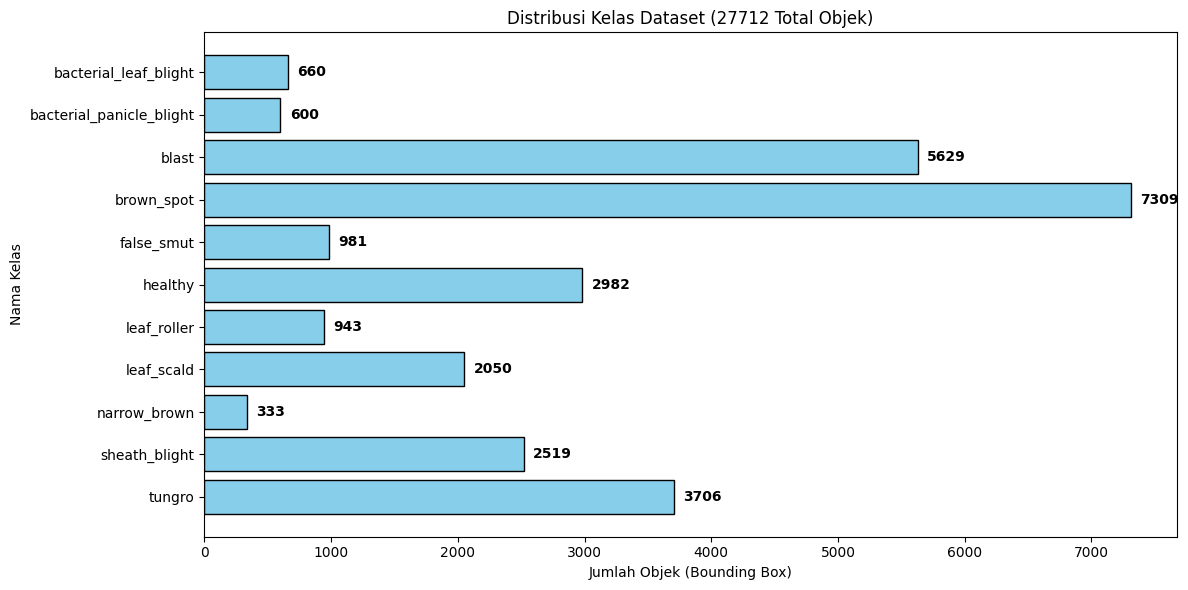

In [12]:
urutan = sorted(CLASS_NAMES)
nama = [CLASS_NAMES[i] for i in urutan]
nilai = [jumlah[i] for i in urutan]

plt.figure(figsize=(12, 6))
bars = plt.barh(nama, nilai, color="skyblue", edgecolor="black")
offset = max(nilai) * 0.01 if nilai and max(nilai) > 0 else 1
for bar in bars:
    plt.text(bar.get_width() + offset, bar.get_y() + bar.get_height() / 2,
             f"{int(bar.get_width())}", ha="left", va="center", fontweight="bold")
plt.xlabel("Jumlah Objek (Bounding Box)")
plt.ylabel("Nama Kelas")
plt.title(f"Distribusi Kelas Dataset ({total_objek} Total Objek)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

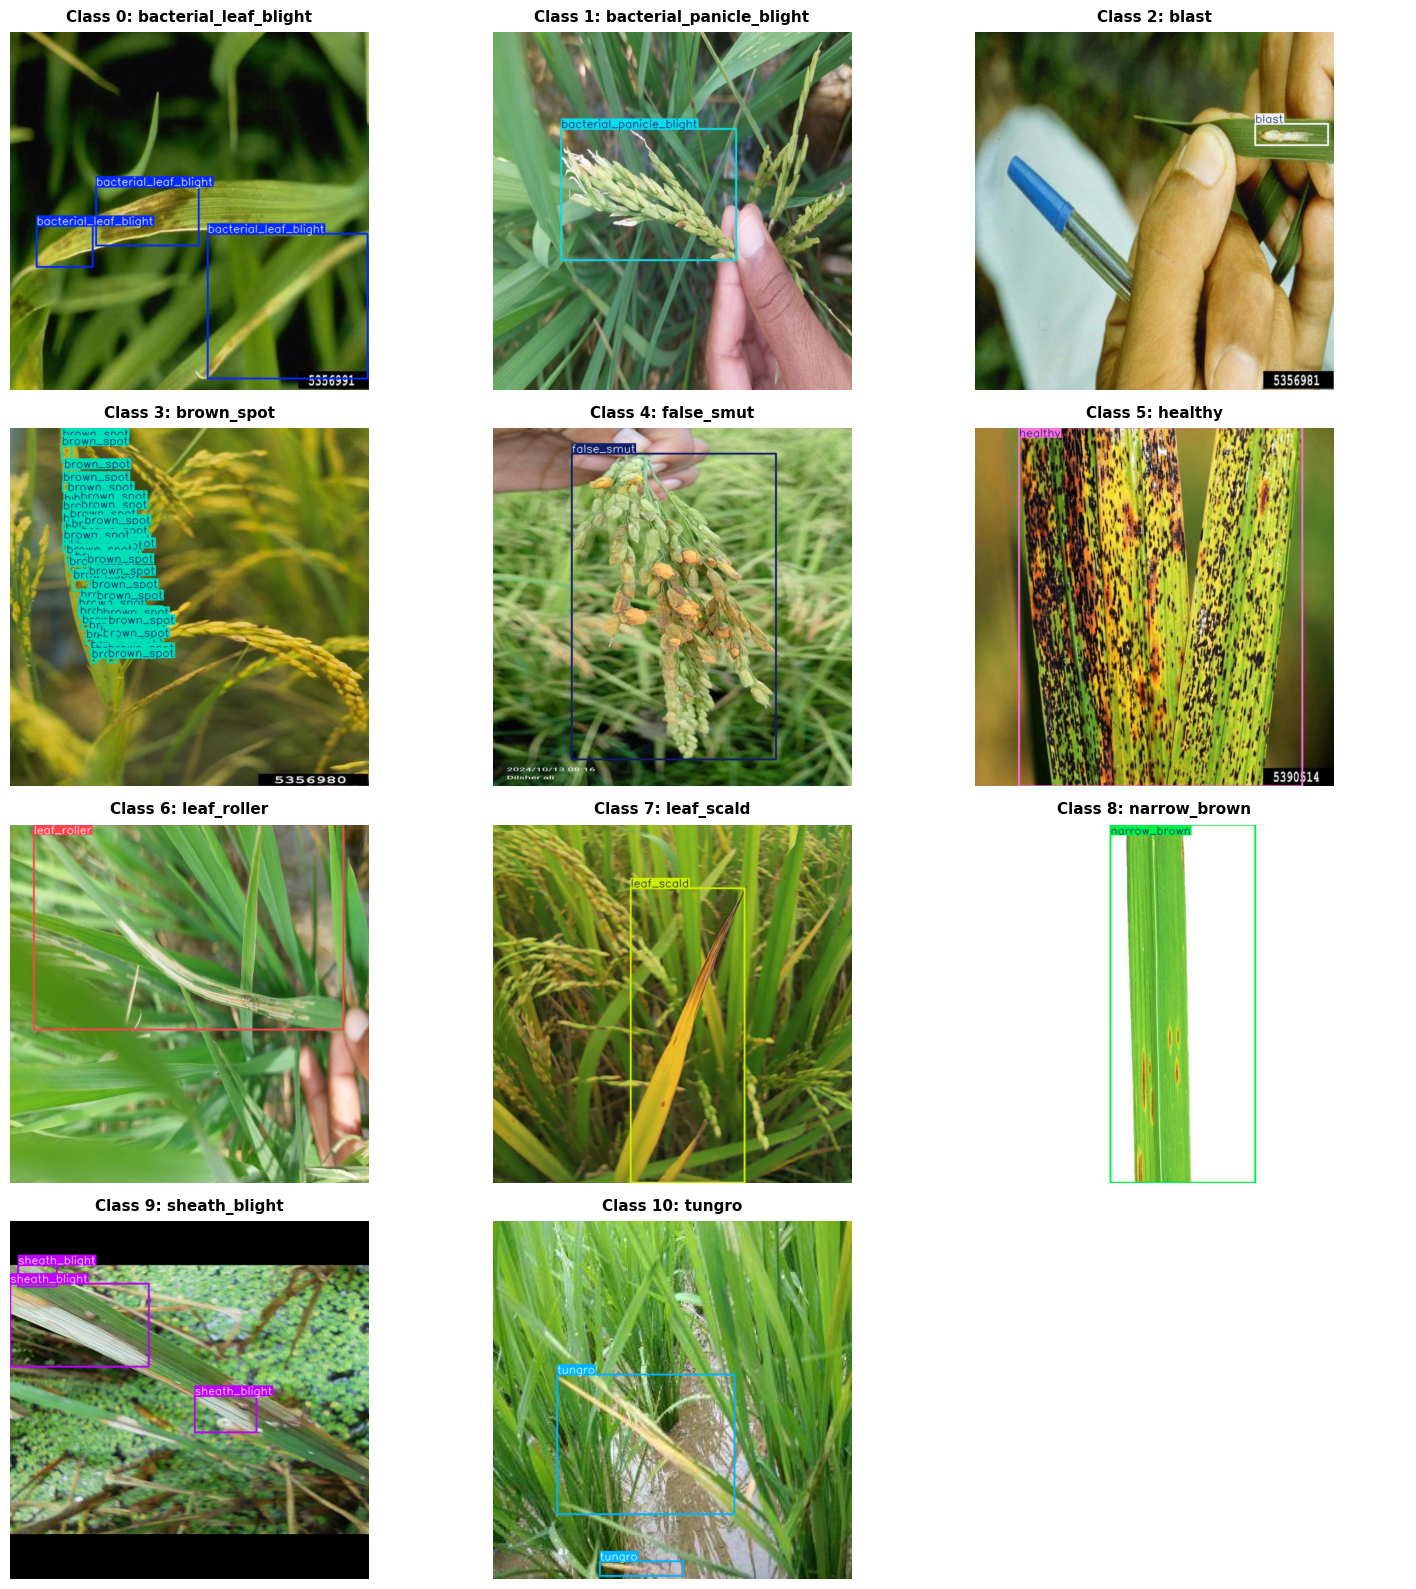

In [13]:
images_dir = DATASET_DIR / "images" / "train"
labels_dir = DATASET_DIR / "labels" / "train"

# Ambil satu contoh untuk setiap kelas (diurutkan agar hasilnya selalu sama)
contoh_per_kelas = {}
for label_file in sorted(labels_dir.glob("*.txt")):
    if len(contoh_per_kelas) == len(CLASS_NAMES):
        break
    kotak = baca_label(label_file)
    if not kotak:
        continue
    img_file = cari_gambar(images_dir, label_file.stem)
    if img_file is None:
        continue
    for cls_id, *_ in kotak:
        contoh_per_kelas.setdefault(cls_id, (img_file, label_file))

axes = buat_grid(len(CLASS_NAMES), cols=3, tinggi=4)
for ax, cls_id in zip(axes, sorted(CLASS_NAMES)):
    if cls_id in contoh_per_kelas:
        img_path, label_path = contoh_per_kelas[cls_id]
        img = cv2.imread(str(img_path))
        h, w = img.shape[:2]
        annotator = Annotator(img, line_width=2)
        for c_id, xc, yc, bw, bh in baca_label(label_path):
            box = [(xc - bw / 2) * w, (yc - bh / 2) * h, (xc + bw / 2) * w, (yc + bh / 2) * h]
            annotator.box_label(box, CLASS_NAMES[c_id], color=colors(c_id, True))
        ax.imshow(cv2.cvtColor(annotator.result(), cv2.COLOR_BGR2RGB))
        ax.set_title(f"Class {cls_id}: {CLASS_NAMES[cls_id]}", fontsize=11, fontweight="bold", pad=8)
    else:
        ax.text(0.5, 0.5, f"Tidak ada sampel untuk\nClass {cls_id}: {CLASS_NAMES[cls_id]}",
                ha="center", va="center", color="red", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Training

Latih YOLO26l dari konfigurasi awal pada data training dengan hyperparameter yang ditetapkan. Tahap ini menghasilkan bobot terbaik untuk evaluasi dan inferensi.


In [14]:
if TRAIN:
    model = YOLO("yolo26l.yaml")
    model.train(
        data=str(DATASET_YAML),
        epochs=EPOCHS,
        imgsz=IMGSZ,
        pretrained=False,
        batch=BATCH,
        device=DEVICE,
        hsv_h=0.01,
        hsv_s=0.4,
        hsv_v=0.4,
        erasing=0.2,
        fliplr=0.3,
        flipud=0.3,
        mosaic=0.7,
        patience=30,
        seed=SEED,
        project=str(RUNS_DIR),   # hasil selalu di RUNS_DIR/train, tidak bergantung folder kerja Ultralytics
        name="train",
        exist_ok=True,
    )
else:
    print("TRAIN = False, training dilewati.")

Ultralytics 8.4.187 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/Dataset_Telepati/dataset.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=300, erasing=0.2, exist_ok=True, fliplr=0.3, flipud=0.3, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.4, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26l.yaml, moment

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      2/300      11.1G      3.342      5.991    0.06405         27        640: 100% ━━━━━━━━━━━━ 317/317 1.3it/s 4:02
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 33/33 1.6it/s 20.2s
                   all       2106       4887      0.504     0.0657     0.0294    0.00796

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      3/300      11.1G      2.557      4.055    0.04506         45        640: 100% ━━━━━━━━━━━━ 317/317 1.4it/s 3:45
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 33/33 1.6it/s 20.6s
                   all       2106       4887      0.206     0.0451     0.0098    0.00278

      Epoch    GPU_mem   box_loss   cls_loss    l1_loss  Instances       Size
      4/300      11.2G       2.24      3.572    0.03486         33        640: 100% ━━━━━━━━━

## Evaluasi

Evaluasi bobot terpilih pada split test, lalu hitung mAP, precision, recall, dan F1 untuk mengukur performa pada data yang tidak digunakan saat training.


In [15]:
def pilih_bobot():
    if WEIGHTS_OVERRIDE:
        override = Path(WEIGHTS_OVERRIDE).expanduser()
        if override.is_file():
            return override.resolve()
        raise FileNotFoundError(f"WEIGHTS_OVERRIDE tidak ditemukan: {override}")
    if BEST_WEIGHTS.is_file():
        return BEST_WEIGHTS
    raise FileNotFoundError(
        f"Bobot tidak ditemukan di {BEST_WEIGHTS}. Jalankan training (TRAIN = True) atau isi WEIGHTS_OVERRIDE."
    )
WEIGHTS = pilih_bobot()

model = YOLO(str(WEIGHTS))
m = model.val(data=str(DATASET_YAML), split="test", imgsz=IMGSZ,
              project=str(RUNS_DIR), name="val_test", exist_ok=True)
b = m.box

print(f"mAP50    : {b.map50:.4f}")
print(f"mAP50-95 : {b.map:.4f}")
print(f"F1 dari mean P dan R                  : {2 * b.mp * b.mr / (b.mp + b.mr + 1e-9):.4f}  (P={b.mp:.3f}, R={b.mr:.3f})")

for i, c in enumerate(b.ap_class_index):
    print(f"{m.names[c]:24s} AP50={b.ap50[i]:.3f}  F1={b.f1[i]:.3f}")

Ultralytics 8.4.187 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26l summary (fused): 188 layers, 24,754,221 parameters, 0 gradients, 86.5 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 21.1±29.2 MB/s, size: 42.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /kaggle/working/Dataset_Telepati/labels/test... 1054 images, 5 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1059/1059 675.3it/s 1.6s
val: New cache created: /kaggle/working/Dataset_Telepati/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 67/67 1.4it/s 48.1s
                   all       1059       2669       0.73      0.721      0.717      0.515
 bacterial_leaf_blight         29         59       0.47      0.492      0.408      0.201
bacterial_panicle_blight         27         27      0.893      0.926  

## Inferensi

Jalankan prediksi pada contoh gambar test dan tampilkan bounding box untuk memperlihatkan keluaran model secara visual.


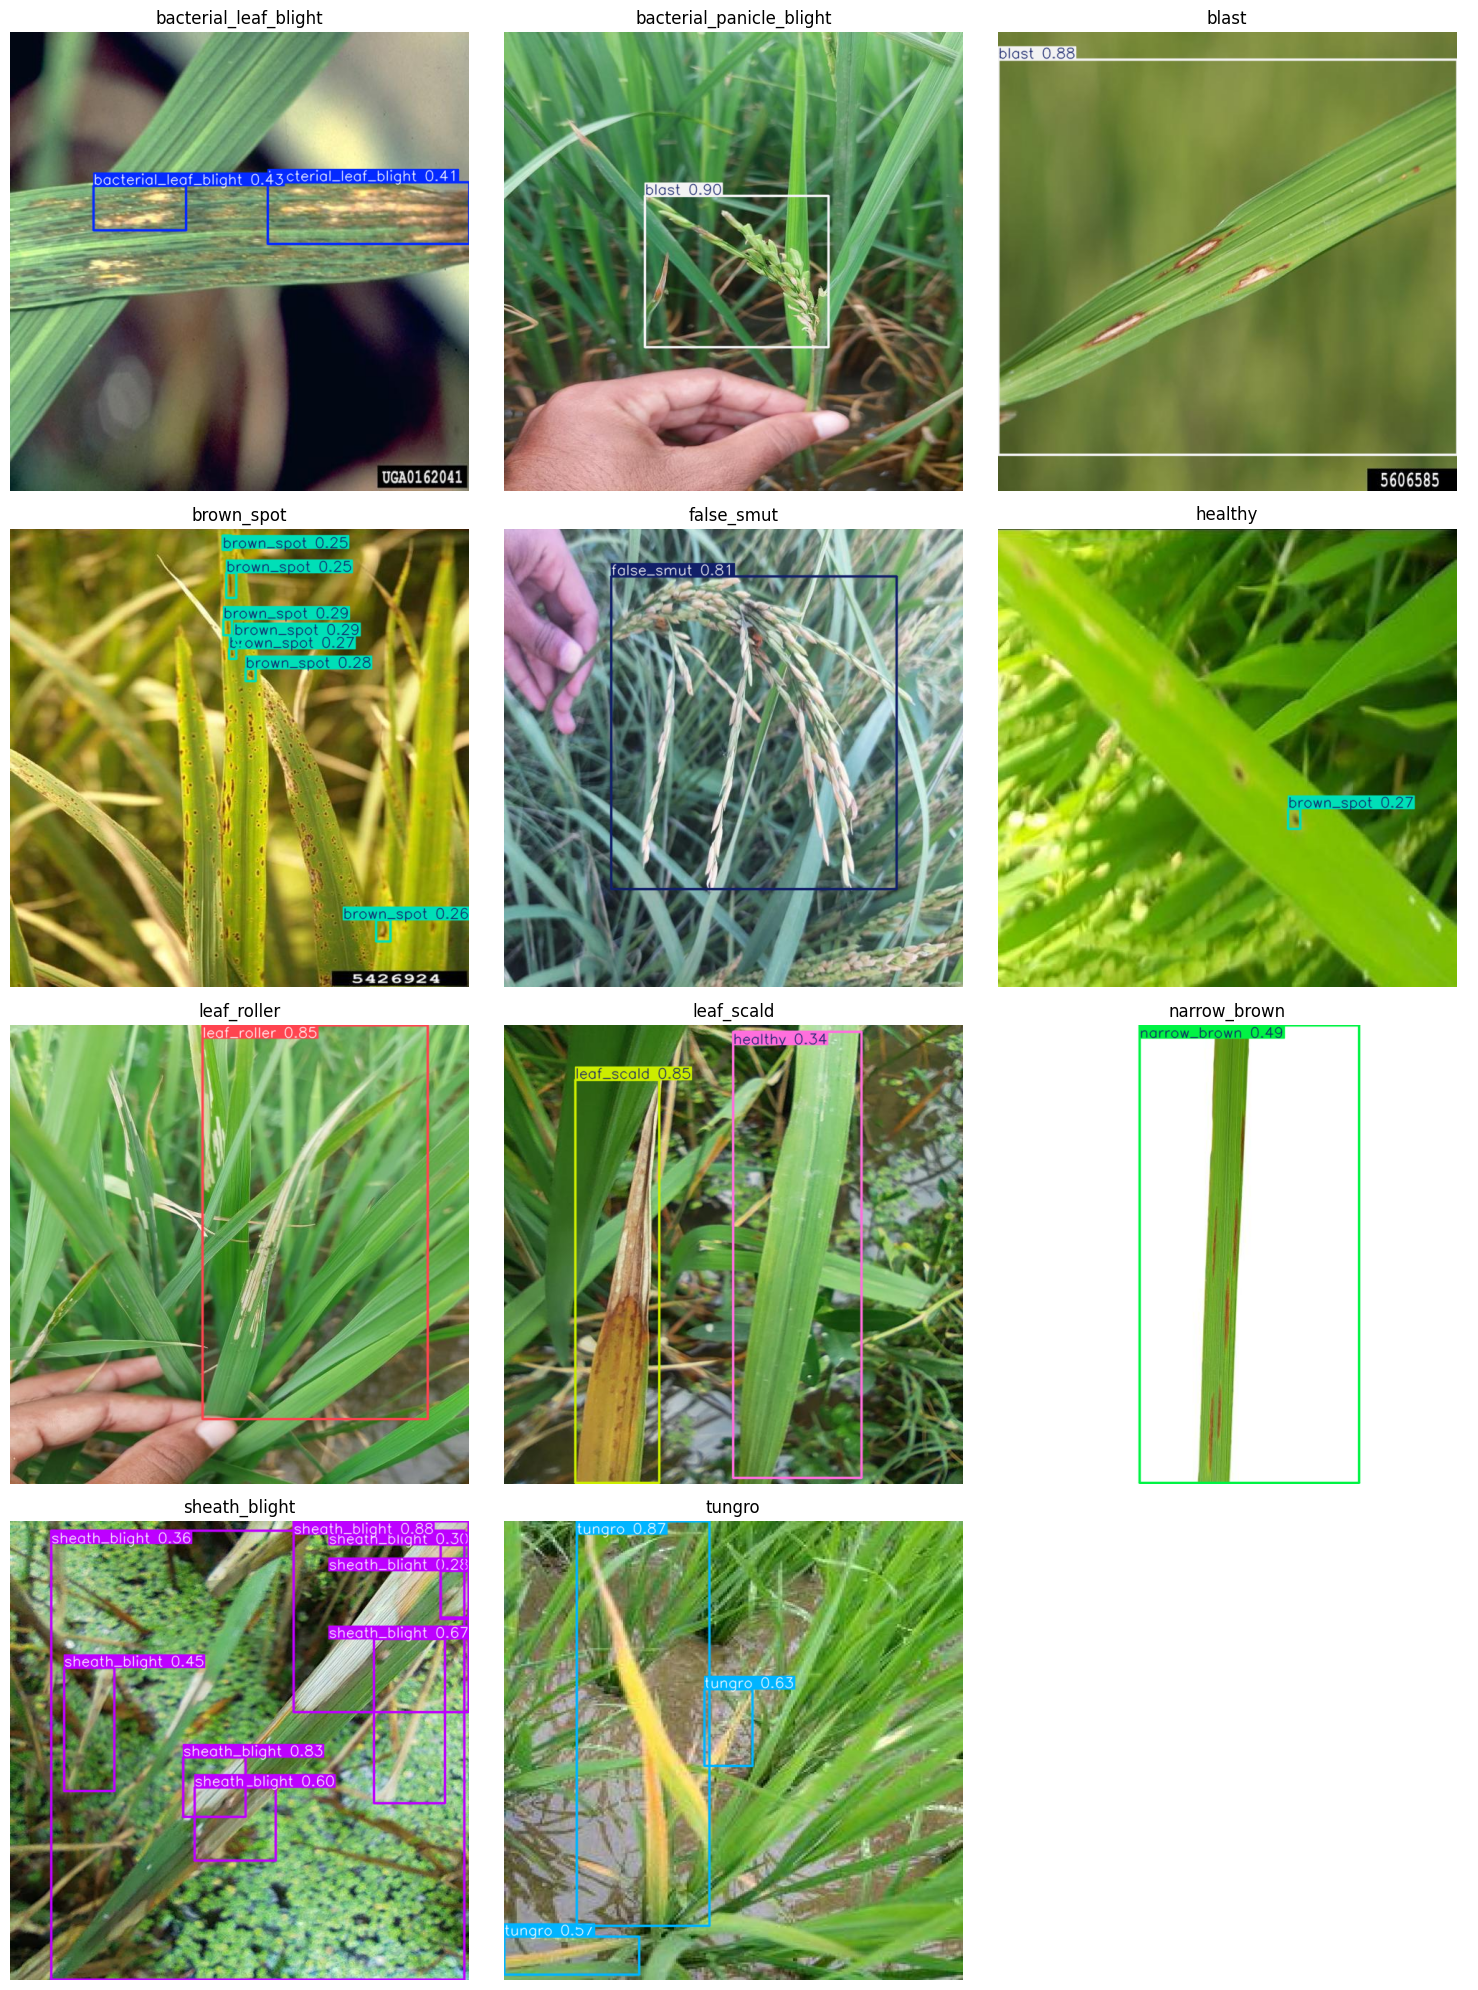

In [16]:
folder_gambar = DATASET_DIR / "images" / "test"
folder_label = DATASET_DIR / "labels" / "test"

contoh = {}
for label in sorted(folder_label.glob("*.txt")):
    for kelas in {cls_id for cls_id, *_ in baca_label(label)}:
        contoh.setdefault(kelas, label.stem)

axes = buat_grid(len(contoh), cols=3, tinggi=5)
for ax, (kelas, nama_file) in zip(axes, sorted(contoh.items())):
    gambar = cari_gambar(folder_gambar, nama_file)
    hasil = model.predict(str(gambar), conf=0.25, verbose=False)[0]
    ax.imshow(hasil.plot()[..., ::-1])   # BGR -> RGB
    ax.set_title(CLASS_NAMES[kelas])
    ax.axis("off")
plt.tight_layout()
plt.show()